# Homework 4 - MTH 602 - Coding Questions

William Girard

Due Date: Monday, October 26th, 2026

## Chapter 3: Multivariate Gaussian Mixture Modeling

Problem context:  Probability mixture modeling is used throughout science and engineering.  For example, see a 
multi-component Gaussian mixture model for pulsar classification (https://arxiv.org/pdf/1205.6221, Fig. 2). 
In this assignment, the you will proceed from a 1-component to a 2-component mixture model, using diagnostics 
to check model correctness.  In class the basics of 2D Gaussians and mixture models were outlined.  To complete 
this assignment it may be helpful to consult the scikit-learn documentation on fitting GMMs from samples (https:
//scikit-learn.org/stable/modules/mixture.html).

The exercises use 2D data to explore Gaussian Mixture Models (GMMs). Hints given throughout this assignment 
will assume Python with scikit-learn and the following modules:

``` python
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
import numpy as np
```
Use the following function to generate ground-truth samples in Stages 1 and 2.

``` python
def sample_2d_gaussian(mu, Sigma, n, rng=None):
if rng is None:
 rng = np.random.default_rng()
return rng.multivariate_normal(mean=mu, cov=Sigma, size=n)
```

### Stage 1 — One Gaussian: MLE vs. GMM with 1 component

Let the ground-truth Gaussian be

$$
\mu = (2, -1), \qquad \Sigma = \begin{bmatrix} 2 & 0.8 \\ 0.8 & 1 \end{bmatrix},
$$

and write $\vec{x} = (x_1, x_2)$. Draw $N = 1000$ samples $\vec{x} \sim \mathcal{N}(\mu, \Sigma)$ using `sample_2d_gaussian`, then:

1. Visualization: Make a scatter plot of the samples

In [50]:
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
import matplotlib.pyplot as plt
import numpy as np

In [51]:
def sample_2d_gaussian(mu, Sigma, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    return rng.multivariate_normal(mean=mu, cov=Sigma, size=n)

In [52]:
rng = np.random.default_rng(42)

# given values
mu = [2, - 1]

sigma = np.array([[2, 0.8],
                  [0.8,1]])
N = 1000

samples = sample_2d_gaussian(mu, sigma, N, rng)
samples.shape

(1000, 2)

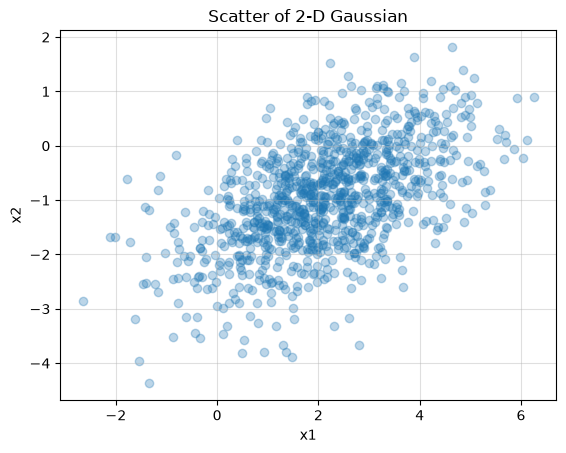

In [53]:
import matplotlib.pyplot as plt 

x_1 = samples[:, 0]
x_2 = samples[:, 1]
plt.scatter(x_1, x_2, alpha=0.3)
plt.title("Scatter of 2-D Gaussian")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(alpha=0.4)
plt.show()

2. **Analytic maximum-likelihood solution:** From Bishop, the MLEs are

$$
\hat{\mu} = \frac{1}{N} \sum_{i=1}^{N} x_i, \qquad \hat{\Sigma} = \frac{1}{N} \sum_{i=1}^{N} (x_i - \hat{\mu})(x_i - \hat{\mu})^\top.
$$

Compute these, report their values, and compare to the ground truth.

In [54]:
# formula is just the mean of the samples
mu_x1_MLE = np.mean(x_1)
mu_x2_MLE = np.mean(x_2)

print(f'Ground truth x1: {mu[0]} - MLE solution: {mu_x1_MLE}')
print(f'Ground truth x2: {mu[1]} - MLE solution: {mu_x2_MLE}')
mu_MLE = np.array([mu_x1_MLE,mu_x2_MLE])
mu_MLE

Ground truth x1: 2 - MLE solution: 2.111671768180661
Ground truth x2: -1 - MLE solution: -0.9712643960132001


array([ 2.11167177, -0.9712644 ])

In [55]:
# ground truth variance for x1 --> top left (2)
var_MLE_x1 = ([(x_i - mu_x1_MLE)*(np.transpose(x_i - mu_x1_MLE)) for x_i in x_1])
var_MLE_x1 = np.mean(var_MLE_x1)

# ground truth variance for x2 --> bottom right (1)
var_MLE_x2 = ([(x_i - mu_x2_MLE)*(np.transpose(x_i - mu_x2_MLE)) for x_i in x_2])
var_MLE_x2 = np.mean(var_MLE_x2)

# upper right/lower left is the same, calculated between x1 and x2
var_MLE_x1x2 = ([(x_i_1 - mu_x1_MLE)*(np.transpose(x_i_2 - mu_x2_MLE)) for x_i_1, x_i_2 in zip(x_1, x_2)])
var_MLE_x1x2 = np.mean(var_MLE_x1x2)

print('Ground truth matrix:\n', sigma)
sigma_MLE = np.array([[var_MLE_x1, var_MLE_x1x2], 
                   [var_MLE_x1x2, var_MLE_x2]])

print('\nMLE sigma matrix: \n', sigma_MLE)

Ground truth matrix:
 [[2.  0.8]
 [0.8 1. ]]

MLE sigma matrix: 
 [[2.02549614 0.73995593]
 [0.73995593 0.94376307]]


3. **GMM with one component:** Fit a one-component GMM:

```python
g1 = GaussianMixture(n_components=1, covariance_type='full',
                     n_init=10, random_state=0).fit(X)
```

Extract $\mu_{\text{gmm}}$ and $\Sigma_{\text{gmm}}$. Then compare to the maximum-likelihood solution using

$$
\|\hat{\mu} - \mu_{\text{gmm}}\|_2 \text{ (vector } L^2 \text{ norm)}, \qquad \|\hat{\Sigma} - \Sigma_{\text{gmm}}\|_2 \text{ (matrix 2-norm)}.
$$

Agreement should be very close.

In [56]:
g1 = GaussianMixture(n_components=1, covariance_type='full',
n_init=10, random_state=0).fit(samples)

In [57]:
# extract mean and compare using L2 norm

mu_gmm = g1.means_
l2_norm = np.linalg.norm(mu_gmm-mu_MLE)
print(f'Mean GMM: {mu_gmm} - MLE Mean: {mu_MLE} - L2-Norm: {l2_norm}')

Mean GMM: [[ 2.11167177 -0.9712644 ]] - MLE Mean: [ 2.11167177 -0.9712644 ] - L2-Norm: 3.3306690738754696e-16


In [58]:
# extract covariance and compare with l2 norm

sigma_gmm = g1.covariances_ 
l2_norm = np.linalg.norm(sigma_gmm[0]-sigma_MLE, 2)
print(f'Sigma GMM: {sigma_gmm}\nMLE Sigma: {sigma_MLE}\nL2-Norm: {l2_norm}')

Sigma GMM: [[[2.02549714 0.73995593]
  [0.73995593 0.94376407]]]
MLE Sigma: [[2.02549614 0.73995593]
 [0.73995593 0.94376307]]
L2-Norm: 1.0000000002083936e-06


4. Sampling from the fitted model: Use g1.sample(M) to draw new points; overlay them on the original
scatter plot as color-coded points so as to distinguish them from the original 1000 samples.

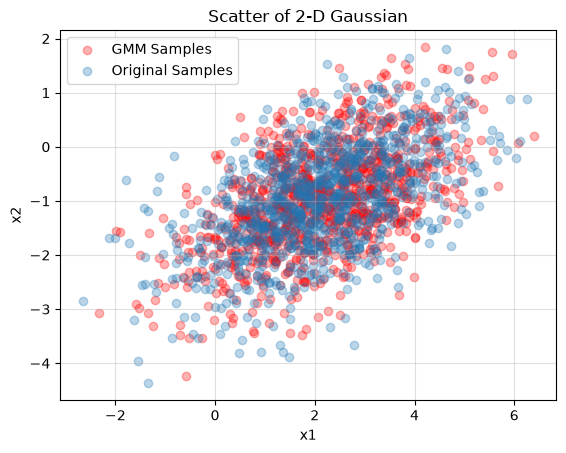

In [59]:
import matplotlib.pyplot as plt 

new_samples = g1.sample(N)
new_samples = new_samples[0] # samples return as a tuple

x_1_new = new_samples[:, 0]
x_2_new = new_samples[:, 1]

plt.scatter(x_1_new, x_2_new, color = 'red', alpha=0.3, label='GMM Samples')
plt.scatter(x_1, x_2, alpha=0.3, label='Original Samples')
plt.title("Scatter of 2-D Gaussian")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

### Stage 2 — Two-Component Mixture in 2D: Fit, Compare, Sample, Classify

Let the ground-truth mixture be

$$
w = (0.2, 0.8), \quad \mu_1 = (0, 0),\ \Sigma_1 = \begin{bmatrix} 1 & 0.6 \\ 0.6 & 1.5 \end{bmatrix}; \qquad \mu_2 = (4, 3),\ \Sigma_2 = \begin{bmatrix} 1.2 & -0.5 \\ -0.5 & 0.8 \end{bmatrix},
$$

with $\vec{x} = (x_1, x_2)$. Motivated by pulsar classification (Fig. 2 of the linked paper above), assume pulsars of "type 1" are drawn from $\mathcal{N}(\vec{x} \mid \mu_1, \Sigma_1)$ and "type 2" from $\mathcal{N}(\vec{x} \mid \mu_2, \Sigma_2)$. To make the connection to pulsars more explicit, you can view $x_1 = P$ (period) and $x_2 = \dot{P}$ (spin-down). The observed pulsar population is thus

$$
P(\vec{x}) = 0.2\, \mathcal{N}(\vec{x} \mid \mu_1, \Sigma_1) + 0.8\, \mathcal{N}(\vec{x} \mid \mu_2, \Sigma_2),
$$

so "type 2" occurs 80% of the time.

Draw $N = 1000$ samples by first sampling the component index (probabilities 0.2 and 0.8), then sampling from the corresponding Gaussian via the provided function.

1. Visualization: Scatter plot the data. For plotting, color each point by its true component label (e.g., red
for type 1, black for type 2).

In [60]:
# reclare rng so this code can be run on its own

rng = np.random.default_rng(42)

# given values
w = np.array([0.2, 0.8])
mus = [np.array([0.0, 0.0]), np.array([4.0, 3.0])]
Sigmas = [np.array([[1.0, 0.6], [0.6, 1.5]]),
          np.array([[1.2, -0.5], [-0.5, 0.8]])]
N = 1000


z = rng.choice(len(w), size=N, p=w) # draw 0 or 1 1000 times at defined weights
values, counts = np.unique(z, return_counts=True)
print(f'0-type: {counts[0]} - 1-type: {counts[1]}') # should be close to 200/800

0-type: 218 - 1-type: 782


In [61]:
# now actually draw the data

X_1 = sample_2d_gaussian(mus[0], Sigmas[0], counts[0], rng)
X_2 = sample_2d_gaussian(mus[1], Sigmas[1], counts[1], rng)

X = [X_1, X_2] 

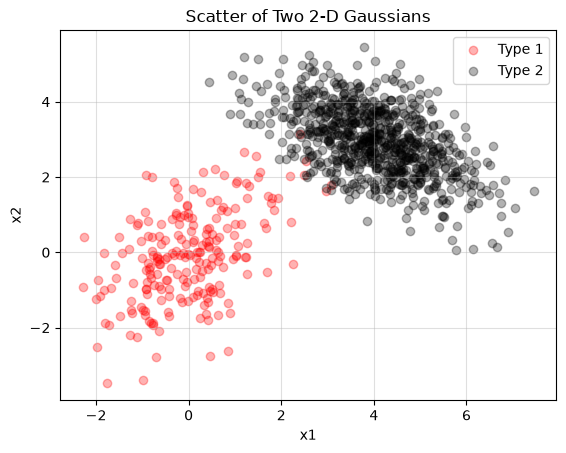

In [62]:
plt.scatter(X[0][:, 0], X[0][:, 1], color = 'red', alpha=0.3, label='Type 1')
plt.scatter(X[1][:, 0], X[1][:, 1], color = 'black', alpha=0.3, label='Type 2')
plt.title("Scatter of Two 2-D Gaussians")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

2. Modeling: Fit GMMs with 𝐾 = 1 and 𝐾 = 2. Also report diagnostics to decide which model is better (e.g.,
log-likelihood, Bayesian information criterion, or qualitative sampling comparisons). For example you could
do: 

``` python
logL1, bic1 = g1.score(X)*len(X), g1.bic(X)
logL2, bic2 = g2.score(X)*len(X), g2.bic(X)
```

In [63]:
X = np.vstack([X_1, X_2])  # necessary for GMM

gk1 = GaussianMixture(n_components=1, covariance_type='full',
n_init=10, random_state=0).fit(X)

gk2 = GaussianMixture(n_components=2, covariance_type='full',
n_init=10, random_state=0).fit(X)

In [64]:
logL1, bic1 = gk1.score(X)*len(X), gk1.bic(X)
logL2, bic2 = gk2.score(X)*len(X), gk2.bic(X)

print('Metrics for Gaussian K1: ', logL1, bic1)
print('Metrics for Gaussian K2: ', logL2, bic2)

Metrics for Gaussian K1:  -3800.7605929364136 7636.059962267738
Metrics for Gaussian K2:  -3244.6852464257645 6565.3558009203325


The K2 GMM is preferred. For logL2 (total log-likelihood), the higher the score, the better. In this case, the GMM with K=2 has the higher logL2. For the second metric (Bayesian Information Criterion), lower is better. This metric introduces a penality for model complexity. Even with this penality, GMM with K=2 still achieves the better (lower) score.

In [65]:
# extract values from gk2

means2, covs2, weights2 = gk2.means_, gk2.covariances_, gk2.weights_
means2, covs2, weights2

(array([[ 4.0030947 ,  2.95177126],
        [-0.07141624, -0.14379587]]),
 array([[[ 1.26360754, -0.52400701],
         [-0.52400701,  0.83549695]],
 
        [[ 0.88099787,  0.47380958],
         [ 0.47380958,  1.36543989]]]),
 array([0.78807205, 0.21192795]))

In [66]:
# can't exactly compare the predicted means/covs/weights to the true values because they are out of order
# but you can kind of tell based on which ones are closest

# compare with type 1:
print('Means (mus): ')
print(f'Type 1 - mus: {mus[0]} - Predicted mus: {means2[1]} - L2-Norm: {np.linalg.norm(means2[1]-mus[0])}')
print(f'Type 2 - mus: {mus[1]} - Predicted mus: {means2[0]} - L2-Norm: {np.linalg.norm(means2[0]-mus[1])}')

print('Sigmas: ')
print(f'Type 1 - Sigma:\n {Sigmas[0]}\n\n Predicted Sigma:\n {covs2[1]}\n\n L2-Norm: {np.linalg.norm(covs2[1]-Sigmas[0], 2)}\n')
print(f'Type 2 - Sigma:\n {Sigmas[1]}\n\n Predicted Sigma:\n\n {covs2[0]}\n\n L2-Norm: {np.linalg.norm(covs2[0] - Sigmas[1], 2)}')

print(f'Weights: {w} - Predicted weights: {weights2[::-1]} - L2-Norm: {np.linalg.norm(weights2[::-1] - w)}')

Means (mus): 
Type 1 - mus: [0. 0.] - Predicted mus: [-0.07141624 -0.14379587] - L2-Norm: 0.16055383210297752
Type 2 - mus: [4. 3.] - Predicted mus: [4.0030947  2.95177126] - L2-Norm: 0.048327930552050376
Sigmas: 
Type 1 - Sigma:
 [[1.  0.6]
 [0.6 1.5]]

 Predicted Sigma:
 [[0.88099787 0.47380958]
 [0.47380958 1.36543989]]

 L2-Norm: 0.25321108050816515

Type 2 - Sigma:
 [[ 1.2 -0.5]
 [-0.5  0.8]]

 Predicted Sigma:

 [[ 1.26360754 -0.52400701]
 [-0.52400701  0.83549695]]

 L2-Norm: 0.07737108477528234
Weights: [0.2 0.8] - Predicted weights: [0.21192795 0.78807205] - L2-Norm: 0.016868670137882995


4. Sampling from the fitted model: Use g2.sample(M) to sample 𝑀 times from the GMM. And overlay these new samples on the true data samples. Comment on coverage of both modes.

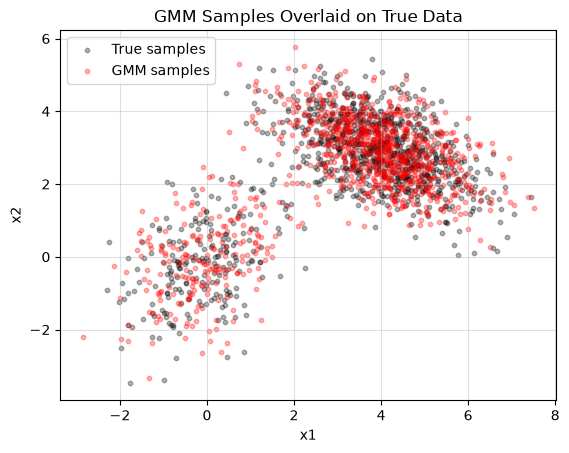

In [67]:
X_gmm, _ = gk2.sample(N)
X_true = np.vstack([X_1, X_2])

plt.scatter(X_true[:, 0], X_true[:, 1], color='black', alpha=0.3, s=10, label='True samples')
plt.scatter(X_gmm[:, 0], X_gmm[:, 1], color='red', alpha=0.3, s=10, label='GMM samples')
plt.title("GMM Samples Overlaid on True Data")
plt.xlabel("x1"); plt.ylabel("x2")
plt.grid(alpha=0.4)
plt.legend()
plt.show()


The coverage seems pretty solid to me. The 20%, 80% split is even more clear with the increase in samples, with the top right Gaussian appearing very dense. For each mode, the GMM seems like it correctly identified the two Gaussians. By looking at the two shapes, a singular Gaussian would have a large cluster of red points in the center, averaging the two. The fact that the red points (GMM samples) are correctly spread out and not in the middle is a good sign the model worked.

5. **Classification**: Now construct your own ground truth data by gathering $X_{\text{data}}$ by sampling from $P(\vec{x})$. Make sure to store the pulsar type labels. Now, test the GMM model by predicting the pulsar classes:

```python
predicted_labels = g2.predict(X_data)
```

Plot points colored by predicted labels as a visual check. Compute the classifier's accuracy against the true label and report the confusion matrix.

In [68]:
rng = np.random.default_rng(123456)  # new seed for unseen samples

# still the same given values
# just rewrote here so code can be run isolated
w = np.array([0.2, 0.8])
mus = [np.array([0.0, 0.0]), np.array([4.0, 3.0])]
Sigmas = [np.array([[1.0, 0.6], [0.6, 1.5]]),
          np.array([[1.2, -0.5], [-0.5, 0.8]])]
N = 1000


z = rng.choice(len(w), size=N, p=w) # draw 0 or 1 1000 times at define weights
values, counts = np.unique(z, return_counts=True)
print(f'0-type: {counts[0]} - 1-type: {counts[1]}') # will be slightly different than earlier draw

0-type: 216 - 1-type: 784


In [69]:
X_1 = sample_2d_gaussian(mus[0], Sigmas[0], counts[0], rng)
X_2 = sample_2d_gaussian(mus[1], Sigmas[1], counts[1], rng)

In [70]:
X_data = np.vstack([X_1, X_2]) 

predicted_labels = gk2.predict(X_data)

X_1_pred = X_data[predicted_labels == 0]
X_2_pred = X_data[predicted_labels == 1]

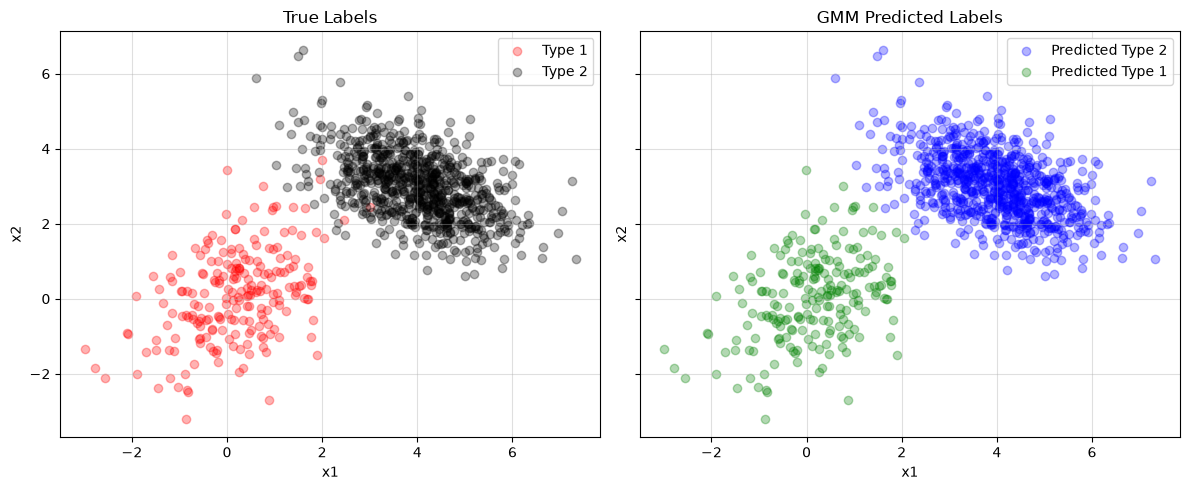

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

axes[0].scatter(X_1[:, 0], X_1[:, 1], color='red', alpha=0.3, label='Type 1')
axes[0].scatter(X_2[:, 0], X_2[:, 1], color='black', alpha=0.3, label='Type 2')
axes[0].set_title("True Labels")

# labels got swapped, X_1 is actually X_2 label
axes[1].scatter(X_1_pred[:, 0], X_1_pred[:, 1], color='blue', alpha=0.3, label='Predicted Type 2')
axes[1].scatter(X_2_pred[:, 0], X_2_pred[:, 1], color='green', alpha=0.3, label='Predicted Type 1')
axes[1].set_title("GMM Predicted Labels")

for ax in axes:
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

In [72]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

y_true = [0] *counts[0] + [1] *counts[1]

# labels were swapped, swap back to correct orientation
y_predicted = [1 if y == 0 else 0 for y in predicted_labels]

cm = confusion_matrix(y_true, y_predicted)
print(cm)
print()
print(f'Accuracy: {100*accuracy_score(y_true, y_predicted)}%')

[[211   5]
 [  0 784]]

Accuracy: 99.5%


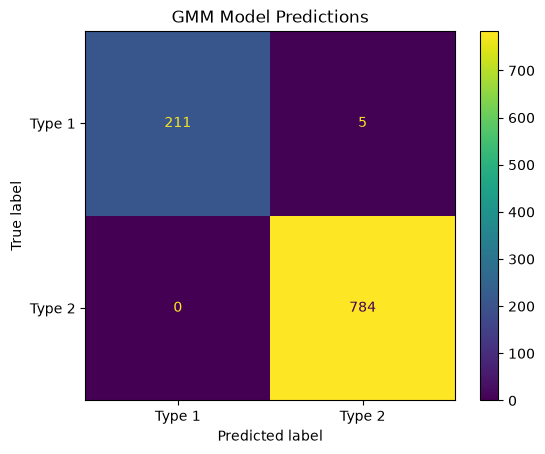

In [73]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Type 1", "Type 2"])
disp.plot()
plt.title("GMM Model Predictions")
plt.show()

## Chapter 4: Polynomial regression with regularization (30 points)

**Context.** In Homework 1 you fit noisy data $\{(t_i, y_i)\}_{i=1}^{N}$ with polynomial least squares, examined conditioning, and studied train/test error vs. degree $M$. In this assignment you will revisit the same task with *ridge* ($\ell_2$) regularization and perform model selection. This corresponds to "regularized least squares" in Section 4.1.6 of the book.

Your testing and training dataset will be generated using a slightly modified version of homework 2's dataset:

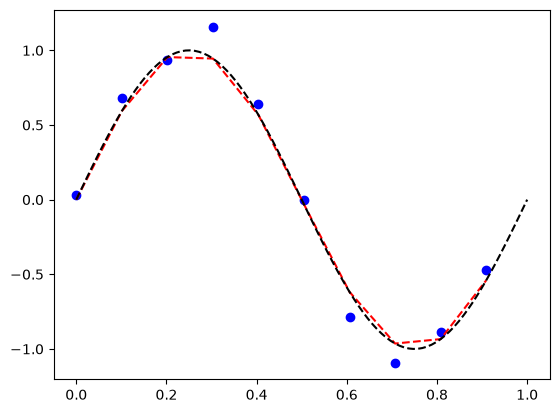

In [74]:

def generate_data(scale_noise, N, seed=None):
    """ Generate a noisy time series dataset {t_i, y_i}_{i=1}^N.
    Parameters
    ----------
    A : float
        Amplitude of the signal (A >= 0)
    N : int
        Number of data points. Time points uniformly sampled from [0, 2pi]
    seed : int or None, optional
        Random seed for reproducibility """

    rng = np.random.default_rng(seed)
    t = np.linspace(0.0, 1.0, N)
    dt = (2*np.pi) / (N - 1)

    A=np.sqrt(np.pi/dt)
    s_hat = np.sqrt(dt / np.pi) * np.sin(2*np.pi*t)   # ||s_hat||_2 == 1 exactly on this grid
    s = A * s_hat
    n = rng.normal(loc=0.0, scale=scale_noise, size=N)
    y = s + n

    return t, y, s, n, s_hat, dt


# generate testing and training data
x_data,y_data,s,n,s_hat, dt = generate_data(.1,100,seed=42)

t_train = x_data[::10]
y_train = y_data[::10]
s_train = s[::10]
plt.plot(t_train,y_train,'bo')
plt.plot(t_train,s_train,'r--')
plt.plot(x_data,s,'k--')

# generate testing data
# TODO for YOU: Write code to remove the training data below
# t_test and y_test will have 90 data points
t_test = np.delete(x_data, slice(None, None, 10)) # taken from https://stackoverflow.com/questions/21922314/removing-every-nth-element-in-an-array
y_test = np.delete(y_data, slice(None, None, 10))

Let $A \in \mathbb{R}^{N \times (M+1)}$ be your polynomial design (Vandermonde) matrix from HW 1 with columns $[1, t, t^2, \ldots, t^M]$. Denote $\omega \in \mathbb{R}^{M+1}$ the coefficients. Consider the ridge optimization problem

$$
\min_{\omega \in \mathbb{R}^{M+1}} \|A\omega - y\|_2^2 \; + \; \lambda \|\Gamma \omega\|_2^2, \qquad \lambda \geq 0.
$$

If $\Gamma = \text{diag}(1, 1, \ldots, 1)$ is the identity, this matches Eq. (4.25) from the Bishop book. Often it is desirable to leave the constant term unpenalized, in which case $\Gamma = \text{diag}(0, 1, 1, \ldots, 1)$. In either case, the corresponding normal equations are

$$
\hat{\omega}_\lambda \; = \; (A^\top A + \lambda \Gamma^\top \Gamma)^{-1} A^\top y,
$$

which can be compared to Eq. (4.27) from the Bishop book.

In what follows, use $\Gamma = \text{diag}(0, 1, 1, \ldots, 1)$.

### Ridge implementation, diagnostics, and interpretation

1. **Implementation & comparison.** Consider all polynomial orders $M \in \{1, 2, \ldots, 9\}$ and regularization factors $\lambda \in \{0, 10^{-6}, 10^{-4}, 10^{-2}, 10^{0}, 10^{2}\}$. There are $9 \times 6 = 54$ $(M, \lambda)$ combinations. For each:

    - Use the training and testing data as shown in the code block above. You should have 10 samples in your training set and 90 samples in your testing set. Use the same testing/training data for *all* $(M, \lambda)$ so results are comparable.
    - Compute $\hat{\omega}_\lambda$ by solving the linear system

    $$
    (A^\top A + \lambda \Gamma^\top \Gamma)\, \hat{\omega}_\lambda = A^\top y
    $$

    - Report train and test MSE, $\kappa(A^\top A)$, and $\kappa\big(A^\top A + \lambda \Gamma^\top \Gamma\big)$ (2-norm condition numbers). Briefly discuss how ridge regularization affects conditioning.
    - For each fixed $M$, plot test MSE vs. $\lambda$ (use a log $\lambda$ axis).
    - Provide evidence (table or plot) showing how the condition number varies with $\lambda$.

In [75]:
import pandas as pd
from sklearn.metrics import mean_squared_error

Ms = range(1, 10)
lams = [0, 1e-6, 1e-4, 1e-2, 1e0, 1e2]
results = []   # list of dictionaries for (M. lam)

def design_matrix(t, M):
    A = np.vander(x=t, N=M+1, increasing=True)
    return A

def ridge_fit(A, y, lam, Gamma):

    K = (A.T @ A) + (lam*(Gamma.T @ Gamma)) 
    b = A.T @ y 

    omega = np.linalg.solve(K, b) # using .solve() to avoid computing the inverse

    return omega, K

for M in Ms:
    A_train = design_matrix(t_train, M)
    A_test = design_matrix(t_test, M)
    Gamma = np.diag([0]+[1]*(M)) # don't penalize y-intercept (w0)

    for lam in lams:
        omega, K = ridge_fit(A_train, y_train, lam, Gamma)

        y_train_pred = A_train @ omega
        train_MSE = mean_squared_error(y_train, y_train_pred)

        y_test_pred = A_test @ omega
        test_MSE = mean_squared_error(y_test, y_test_pred)

        # condition numbers for both regular A^TA and the ridge solution
        cond_AtA = np.linalg.cond(A_train.T @ A_train)
        cond_K = np.linalg.cond(K)

        results.append({'M': M, 'lam': lam, 'mse_train':train_MSE, 'mse_test': test_MSE, 'cond_AtA': cond_AtA, 'cond_K': cond_K}) 

df = pd.DataFrame(results)

df


,M,lam,mse_train,mse_test,cond_AtA,cond_K
0,1,0.000000,2.784508e-01,0.207241,1.773725e+01,1.773725e+01
1,1,0.000001,2.784508e-01,0.207240,1.773725e+01,1.773723e+01
2,1,0.000100,2.784508e-01,0.207238,1.773725e+01,1.773520e+01
3,1,0.010000,2.784940e-01,0.206997,1.773725e+01,1.753453e+01
4,1,1.000000,3.707703e-01,0.289775,1.773725e+01,8.383152e+00
5,1,100.000000,5.863967e-01,0.502663,1.773725e+01,1.054696e+01
6,2,0.000000,2.455061e-01,0.250259,4.533143e+02,4.533143e+02
7,2,0.000001,2.455061e-01,0.250258,4.533143e+02,4.532990e+02
8,2,0.000100,2.455063e-01,0.250095,4.533143e+02,4.517893e+02
9,2,0.010000,2.462636e-01,0.238622,4.533143e+02,3.389373e+02


All values are reported above in a pandas dataframe. The MSE-train is lower than the MSE-test for the more complex models, which makes sense. The exceptions are the simple or heavily penalized models (low M or large lambda), which underfit. The relationship between ridge regularization is pretty clear, especially when you isolate the M=9 version. The cond of (A^TA) doesn't change with different values of lambda, but the condition number of K, does. When lambda=100 and M=9, the larger weights are heavily penalized. This drops the condition number all the way from 1.5e+05 (when lambda=0.00010) to 1.12e+01 (lambda=100), a massive decrease. Of course, it is a balancing act. Penalzing high-value weights may cause the model to become less complex, losing predictive power.

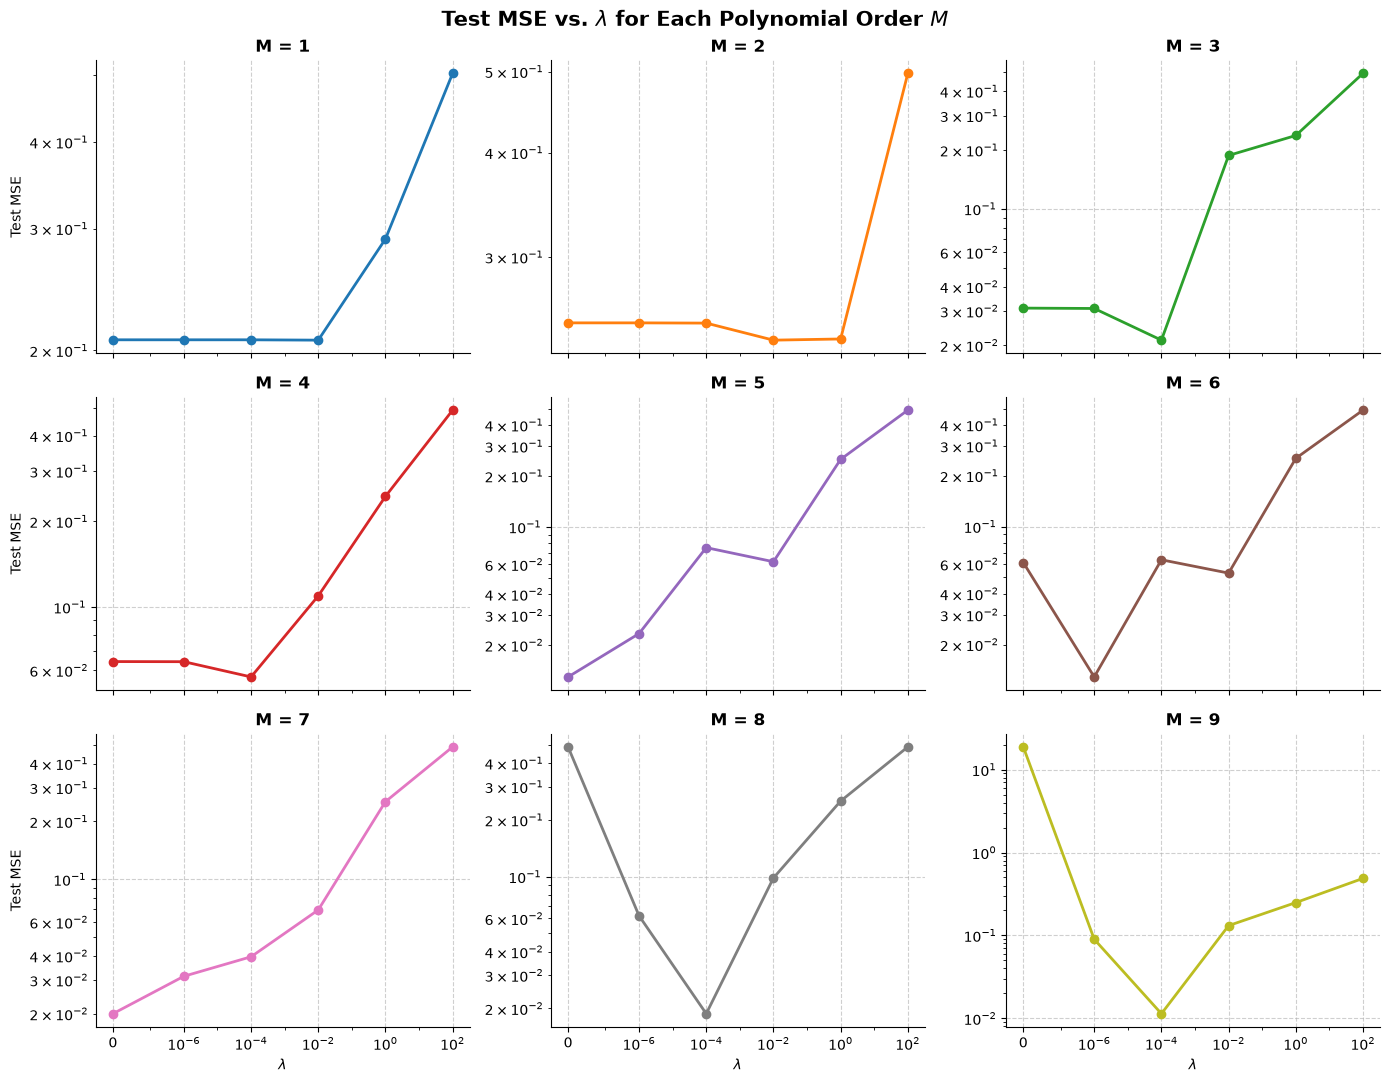

In [76]:
# disclaimer: I originally made my 3x3 plot but it was a little ugly/had overlapping labels, AI tool was used to clean up the plot


fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(14, 11), sharex=True)

for ax, M in zip(axes.flat, Ms):
    sub = df[df['M'] == M]

    ax.plot(sub['lam'], sub['mse_test'], marker='o', color=f"C{M-1}", linewidth=2)

    ax.set_xscale('symlog', linthresh=1e-7)
    ax.set_yscale('log')
    ax.set_xticks(lams)
    ax.set_xticklabels(['0', r'$10^{-6}$', r'$10^{-4}$', r'$10^{-2}$', r'$10^{0}$', r'$10^{2}$'])

    ax.set_title(f"M = {M}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# axis labels only on outer edges
for ax in axes[-1, :]:
    ax.set_xlabel(r'$\lambda$')
for ax in axes[:, 0]:
    ax.set_ylabel('Test MSE')

fig.suptitle(r'Test MSE vs. $\lambda$ for Each Polynomial Order $M$', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


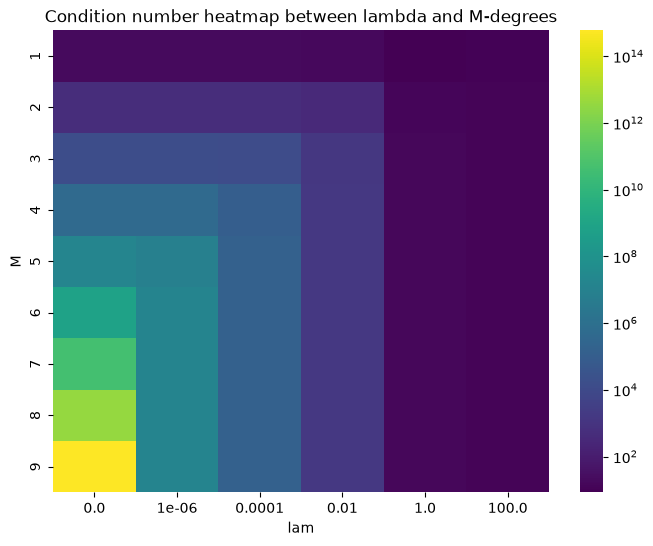

In [77]:
import seaborn as sns 
import matplotlib.colors as mcolors

plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    df.pivot(index='M', columns='lam', values='cond_K'), 
    cmap='viridis', 
    norm=mcolors.LogNorm()  # sets the color scaling to logarithmic
)

plt.title('Condition number heatmap between lambda and M-degrees')
plt.show()

Heamap shown above between lambda and M-degrees. It can be observed that the highest condition number of K is on the bottom left (M=9, lambda=0), while the lowest is the top right (M=1, lambda = 100). This is a nice sanity check for the heatmap.

The bottom left is the most complex model with 0 large weight penalization. This results in a very poorly conditioned matrix. On the other hand, the top right is a super simple linear model that also has a lot of weight penalization. Adding lambda to the diagonal raises the smallest eigenvalues of K, which shrinks the ratio between the largest and smallest eigenvalues, and thus, a low condition number.

2. Equivalence check with scikit-learn. Fit your data with Ridge(alpha=𝜆, fit_intercept=False),
solver='auto' on the same 𝐴 matrix (intercept already included in 𝐴). Verify that the coefficients match
your closed form solution (now penalize all coefficients with Γ = diag(1, 1, … , 1)) for the same (𝑀 , 𝜆) and
unpenalized intercept.

In [78]:
from sklearn.linear_model import Ridge

for M in Ms:
    A_train = design_matrix(t_train, M)
    Gamma_I = np.diag([1]*(M+1)) # penalize everything, like sklearn

    for lam in lams:
        omega_mine, _ = ridge_fit(A_train, y_train, lam, Gamma_I) # no need to return K, not used in this part
        omega_sk = Ridge(alpha=lam, fit_intercept=False, solver='auto').fit(A_train, y_train).coef_

        # gets pretty ugly printing that many times... so ill print for the first and last degree of M
        
        if(M==1 or M==9):
            rel_err = np.linalg.norm(omega_sk - omega_mine) / np.linalg.norm(omega_mine) # use relative error to normalize for large coefficients
            print(f'Lambda: {lam}, M: {M} - Omega mine: {omega_mine} - Omega SK: {omega_sk} - Relative Error (L2): {rel_err}\n')

Lambda: 0, M: 1 - Omega mine: [ 0.89722852 -1.92879375] - Omega SK: [ 0.89722852 -1.92879375] - Relative Error (L2): 2.1518535646664433e-16

Lambda: 1e-06, M: 1 - Omega mine: [ 0.89722717 -1.92879097] - Omega SK: [ 0.89722717 -1.92879097] - Relative Error (L2): 1.1009532781610602e-15

Lambda: 0.0001, M: 1 - Omega mine: [ 0.89709339 -1.9285162 ] - Omega SK: [ 0.89709339 -1.9285162 ] - Relative Error (L2): 8.687426737088439e-16

Lambda: 0.01, M: 1 - Omega mine: [ 0.88390729 -1.90143164] - Omega SK: [ 0.88390729 -1.90143164] - Relative Error (L2): 2.367882308849431e-16

Lambda: 1.0, M: 1 - Omega mine: [ 0.3474732  -0.79577615] - Omega SK: [ 0.3474732  -0.79577615] - Relative Error (L2): 3.196431049362157e-16

Lambda: 100.0, M: 1 - Omega mine: [ 0.00248305 -0.01498088] - Omega SK: [ 0.00248305 -0.01498088] - Relative Error (L2): 5.26607973103576e-16

Lambda: 0, M: 9 - Omega mine: [ 3.04714148e-02  7.63508639e+01 -1.70115670e+03  1.60792721e+04
 -7.99298426e+04  2.31196430e+05 -4.04038041e+

The solutions match to a high degree of precision for all lambda > 0. The largest difference is at lambda = 0 and M = 9. Since scikit-learn uses a different algorithm and the matrix is extremely poorly conditioned, the small differences can become amplified. Even still, the relative error using the L2 norm is only 0.0004575504734301958, still demonstrating strong cross-model agreement (my manual approach and sklearn's approach).

3. Bias–variance view (qualitative). Using your results, concisely explain how increasing 𝜆 increases bias
and reduces variance, and why the optimal 𝜆⋆ differs across degrees 𝑀.

Increasing lambda introduces bias because it punishes large coefficients by a certain factor, and that factor is determined by the user. The regular linear least squares problem is not biased, the chosen coefficients are the most optimal for our optimization criteria (being the squared L2 norm). The variance is reduced because the more complex models have less "room" to fit to noisy points with their large coefficients. The optimal lambda differs because you ideally want to balance model complexity (degrees of freedom) with regularization. High model complexity necessitates a reasonable lambda, while lower degree models hardly benefit from any value of lambda (5 + 7 never benefit, while other low degrees barely change). All models besides M = 9 (any maybe M=8) have their highest error when lambda = $10^2$, since the weights become over-penalized. 

### Model selection over polynomial degree and regularization

1. Grid search over (𝑀 , 𝜆). Identify the value (𝑀 ̂ , 𝜆 ̂ ) that minimizes test MSE. Report the test MSE at
(𝑀 ̂ , 𝜆).

In [79]:
# simple task here since i have my dataframe

mse = df['mse_test']
idx_min = np.argmin(mse)
print(f'Lowest test MSE occurs at index: {int(idx_min)}, with value: {mse[idx_min]}')

Lowest test MSE occurs at index: 50, with value: 0.011366198622617311


In [80]:
print(f'The specific row is shown below: \n')
print(df.loc[idx_min])

The specific row is shown below: 

M            9.000000e+00
lam          1.000000e-04
mse_train    6.265494e-03
mse_test     1.136620e-02
cond_AtA     5.907849e+14
cond_K       1.515998e+05
Name: 50, dtype: float64


2. **Final reflections** Consider three different fits: (i) the best one $(\hat{M}, \hat{\lambda})$, (ii) a poorly conditioned case $(M, \lambda) = (7, 0)$, (iii) an overly penalized case $(M, \lambda) = (7, 10^0)$.

    - Plot all three fitted curves on the same figure along with the *true (noise-free) signal*.
    - Print the coefficient vectors for all three fits.
    - Comment on how the regularization parameter $\lambda$ affects the coefficients (magnitude and pattern) and how this manifests in the plotted fits. You may wish to revisit the discussion in Chapter 1 and Chapter 4's discussion on bias–variance.

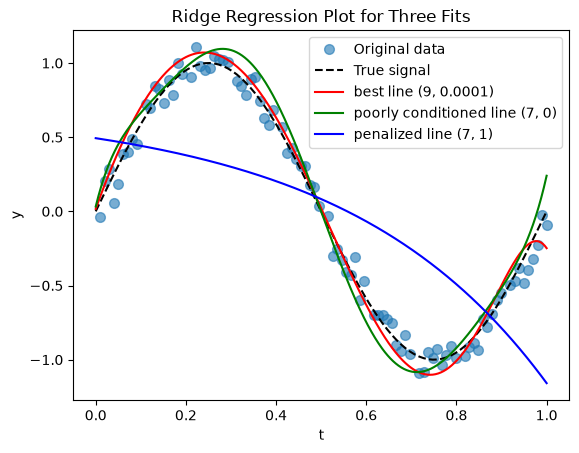

Best Coefficients (9, 0.0001): [  0.01689809   8.45773718 -15.10709582  -9.25696392   3.61923282
  10.338104     9.83331062   4.6518252   -2.61454603 -10.1866247 ]

Poorly Conditioned Coefficients (7, 0): [ 3.21962535e-02  1.24396379e+01 -1.09135840e+02  6.58253817e+02
 -2.08912395e+03  3.25162311e+03 -2.40998727e+03  6.86138264e+02]

Over Penalized Coefficients (7, 1): [ 0.49333088 -0.4633559  -0.4750223  -0.33971027 -0.21102907 -0.11423077
 -0.04675344 -0.00146443]



In [81]:
from numpy.polynomial.polynomial import polyval

def plot_polynomial(coeff_b, coeff_poor, coeff_penalty):
    t_plot = np.linspace(0, 1, 500) # dense grid so the oscillations are visible
    plt.plot(t_test, y_test, 'o', label='Original data', markersize=7, alpha=0.6)
    plt.plot(x_data, s, 'k--', label='True signal')
    plt.plot(t_plot, polyval(t_plot, coeff_b), 'r', label='best line (9, 0.0001)')
    plt.plot(t_plot, polyval(t_plot, coeff_poor), 'g', label='poorly conditioned line (7, 0)')
    plt.plot(t_plot, polyval(t_plot, coeff_penalty), 'b', label='penalized line (7, 1)')
    plt.title(f'Ridge Regression Plot for Three Fits')
    plt.xlabel('t')
    plt.ylabel('y')
    plt.legend()
    plt.show()

# best fit
Gamma_I = np.diag([0] + [1]*(9))
A_train = design_matrix(t_train, M=9)
lam = 1.000000e-04
omega_best, _ = ridge_fit(A_train, y_train, lam, Gamma_I) # no need to return K, not used in this part

# (7, 0) poor fit case
Gamma_I = np.diag([0] + [1]*(7))

A_train = design_matrix(t_train, M=7)
lam = 0
omega_poor_cond, _ = ridge_fit(A_train, y_train, lam, Gamma_I)

# (7, 10^0) overpenalized case
Gamma_I = np.diag([0] + [1]*(7))
A_train = design_matrix(t_train, M=7)
lam = 1e0
omega_penalty, _ = ridge_fit(A_train, y_train, lam, Gamma_I)

plot_polynomial(omega_best, omega_poor_cond, omega_penalty)

print(f'Best Coefficients (9, 0.0001): {omega_best}\n')
print(f'Poorly Conditioned Coefficients (7, 0): {omega_poor_cond}\n')
print(f'Over Penalized Coefficients (7, 1): {omega_penalty}\n')

The differences between the three omegas are very clear. The first line (best coefficients) naturally balances complexity with conditioning. The magnitudes are all reasonable, the total range goes from roughly -15 to 10. The plotted line fits the data well, the best out of all three lines.

The second line, poorly conditioned coefficients, has wildly different values. This points to that this model has overfit to noise using its increased degrees of freedom. This results in worse performance on the testing dataset when compared to the optimal coefficients.

The third line, the over penalized coefficients, is way too simple to fit to the data. This was proved in the math part of this homework. As you increased lambda, the weights go to zero, except for the intercept, which is unpenalized here (Gamma = diag(0, 1, ..., 1)). This results in a constant line at the mean of the training data, which is about y=0 for this sine wave. It can be seen, in both the coefficients and the observed line, that (7, 1) is approaching towards that extreme y=0 case. This results in the blue line having the worst fit to the testing data because of how simple the line.

## Temperature Prediction and Noise Modeling 

**Grading.** Any reasonable attempt earns 20 points. The best temperature prediction model earns +10 bonus points, and the best Gaussian mixture noise model earns +10 bonus points.

**Context.** Consider a temperature sensor that records measurements over time. The temperature changes smoothly, but the measurements are noisy. Most measurements have relatively small errors, while occasionally the sensor produces much larger errors.

We model the measurements as

$$
y(t_i) = s(t_i) + \varepsilon_i, \qquad i = 1, \ldots, N,
$$

where

- $y(t_i)$ is the measured temperature at time $t_i$,
- $s(t)$ is the underlying temperature trend, which you will estimate using regression,
- $\varepsilon_i$ is the measurement noise.

The measurement noise is independently drawn from a two-component Gaussian mixture:

$$
p(\varepsilon) = w_1\, \mathcal{N}(\varepsilon \mid 0, \sigma_1^2) + w_2\, \mathcal{N}(\varepsilon \mid 0, \sigma_2^2),
$$

where $w_1 + w_2 = 1$.

One component represents ordinary sensor noise (small variance), while the other represents occasional unusually noisy measurements (large variance) due to a malfunction.

The dataset `hw4_train.csv` contains the measured temperatures and timestamps $\{(t_i, y_i)\}_{i=1}^{N}$.

**Your tasks:**

1. Temperature regression. Construct a regression model 𝑠(𝑡^) for the underlying temperature trend. You may choose the basis functions, polynomial degree, regularization, or another reasonable regression approach.

In [82]:
# load in data and visualize to guess at good basis functions

df = pd.read_csv('hw4_train.csv')
df.head()

,t,y
0,0.000000,17.917136
1,0.242424,18.159691
2,0.484848,18.532421
3,0.727273,17.822465
4,0.969697,17.874281


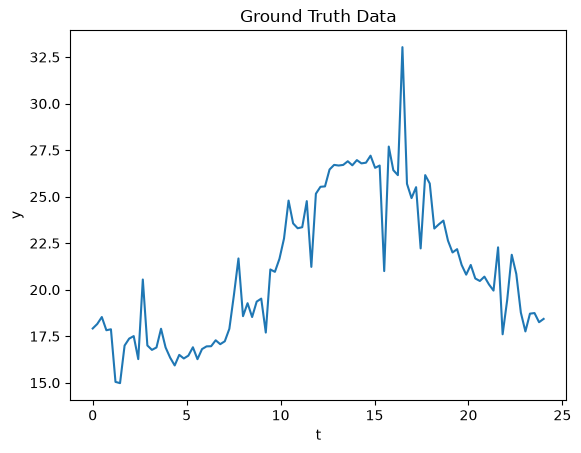

In [83]:
plt.plot(df['t'], df['y'])
plt.title('Ground Truth Data')
plt.xlabel('t')
plt.ylabel('y')
plt.show()

In [84]:
# no idea what the underlying trend might be from that graph
# so ill just go with regular polynomials to start

# rescale t to [0, 1]
df['t'] = df['t']/24

x_data = df['t']
y_data = df['y']

In [85]:
# code credit: https://medium.com/@avijit.bhattacharjee1996/implementing-k-fold-cross-validation-from-scratch-in-python-ae413b41c80d

seed = 42 # fixed seed so the shuffled folds are reproducible

def kfold_indices(data, k):
    fold_size = len(data) // k
    indices = np.random.default_rng(seed).permutation(len(data))
    folds = []
    for i in range(k):
        test_indices = indices[i * fold_size: (i + 1) * fold_size]
        train_indices = np.concatenate([indices[:i * fold_size], indices[(i + 1) * fold_size:]])
        folds.append((train_indices, test_indices))
    return folds

folds = kfold_indices(x_data, 5)

In [86]:
import pandas as pd
from sklearn.metrics import mean_squared_error

# expand M range for the more complex data + lams
Ms = range(1, 13)
lams = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e2]
results = []   # one dict per (M, lam), easy to turn into a DataFrame later

cvs = 5 # number of cross-validation splits

def design_matrix(t, M):
    A = np.vander(x=t, N=M+1, increasing=True)
    return A

def ridge_fit(A, y, lam, Gamma):

    K = (A.T @ A) + (lam*(Gamma.T @ Gamma)) 
    b = A.T @ y 

    omega = np.linalg.solve(K, b) # use .solve() to avoid computing the inverse

    return omega, K

for k, fold in enumerate(folds):

    t_train, y_train = x_data.iloc[fold[0]], y_data.iloc[fold[0]]
    t_test,  y_test  = x_data.iloc[fold[1]], y_data.iloc[fold[1]]


    for M in Ms:
        A_train = design_matrix(t_train, M)
        A_test = design_matrix(t_test, M)
        Gamma = np.diag([0]+[1]*(M)) # don't penalize y-intercept (w0)

        for lam in lams:
            omega, K = ridge_fit(A_train, y_train, lam, Gamma)

            y_train_pred = A_train @ omega
            train_MSE = mean_squared_error(y_train, y_train_pred)

            y_test_pred = A_test @ omega
            test_MSE = mean_squared_error(y_test, y_test_pred)

            # condition numbers for both regular A^TA and the ridge solution
            cond_AtA = np.linalg.cond(A_train.T @ A_train)
            cond_K = np.linalg.cond(K)

            results.append({'k-Fold': k+1, 'M': M, 'lam': lam, 'mse_train':train_MSE, 'mse_test': test_MSE, 'cond_AtA': cond_AtA, 'cond_K': cond_K})   # M, lam, mse_train, mse_test, cond_AtA, cond_K

df_results = pd.DataFrame(results)

In [87]:
# group by M/lambda to get the average across the K-folds + drop that column
df_results = df_results.drop(columns='k-Fold').groupby(['M', 'lam'], as_index=False).mean()

In [88]:
# again, find minimum

idx_min = np.argmin(df_results['mse_test'])
df_results.loc[idx_min]

M            9.000000e+00
lam          1.000000e-06
mse_train    1.863427e+00
mse_test     2.115962e+00
cond_AtA     1.494503e+13
cond_K       1.420764e+08
Name: 73, dtype: float64

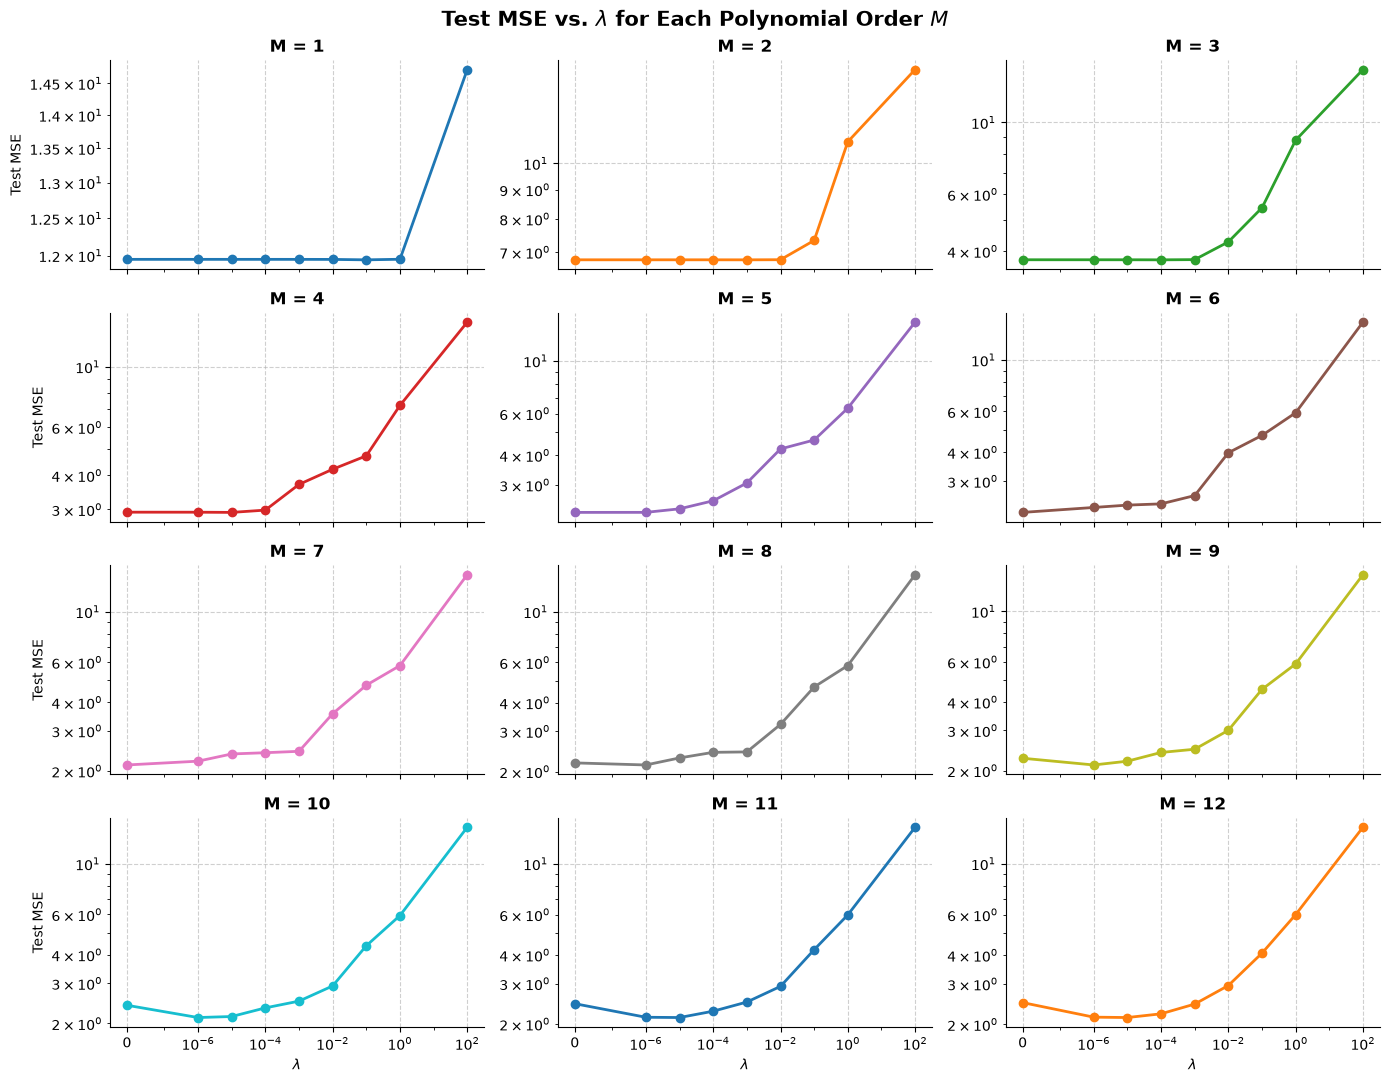

In [89]:
# disclaimer: I originally made my 3x3 plot but it was a little ugly/had overlapping labels, AI tool was used to clean up the plot


fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(14, 11), sharex=True)

for ax, M in zip(axes.flat, Ms):
    sub = df_results[df_results['M'] == M]

    ax.plot(sub['lam'], sub['mse_test'], marker='o', color=f"C{M-1}", linewidth=2)

    ax.set_xscale('symlog', linthresh=1e-7)
    ax.set_yscale('log')
    tick_positions = [0, 1e-6, 1e-4, 1e-2, 1, 100]
    tick_labels = ['0', r'$10^{-6}$', r'$10^{-4}$', r'$10^{-2}$', r'$10^{0}$', r'$10^{2}$']
    ax.set_xticks(tick_positions, labels=tick_labels)

    ax.set_title(f"M = {M}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# axis labels only on outer edges
for ax in axes[-1, :]:
    ax.set_xlabel(r'$\lambda$')
for ax in axes[:, 0]:
    ax.set_ylabel('Test MSE')

fig.suptitle(r'Test MSE vs. $\lambda$ for Each Polynomial Order $M$', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

2. **Noise modeling.** Compute the residuals

$$
r_i = y(t_i) - \hat{s}(t_i).
$$

Fit a two-component Gaussian mixture model to these residuals. Report the component weights, means, and standard deviations.

In [90]:
# optimal "hyperparameters"
M = int(df_results['M'][idx_min])
lam = df_results['lam'][idx_min]

# cross-validation was only for choosing M and lambda, so refit on all the data
Gamma_I = np.diag([0] + [1]*(M))
A_all = design_matrix(x_data, M)
omega_best, _ = ridge_fit(A_all, y_data, lam, Gamma_I)

y_pred = polyval(x_data, omega_best)
residuals = [y_t - y_p for y_t, y_p in zip(y_data, y_pred)]
residuals = np.array(residuals)
residuals = residuals.reshape(-1, 1) # necessary reshape for GMM

In [91]:
g2 = GaussianMixture(n_components=2, covariance_type='full',
n_init=10, random_state=0).fit(residuals)

means2, covs2, weights2 = g2.means_, g2.covariances_, g2.weights_

print(f'Means: {means2}\n\n Covariances: {covs2}\n\n Standard deviations: {np.sqrt(covs2.ravel())}\n\n Weights: {weights2}')

Means: [[-0.06230553]
 [ 0.16024784]]

 Covariances: [[[0.14627939]]

 [[6.33021104]]]

 Standard deviations: [0.38246488 2.51599107]

 Weights: [0.72004231 0.27995769]


3. Model evaluation. Provide plots and diagnostics demonstrating how well your regression and GMM models
describe the data. Briefly explain your modeling choices.

Let's look at the GMM models first with a simple comparison.

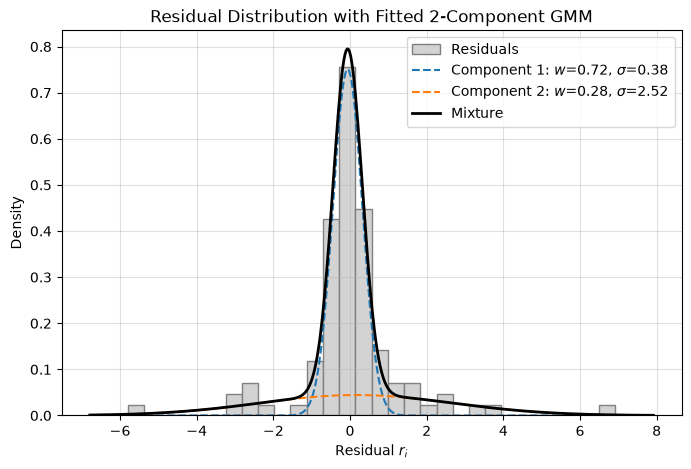

In [92]:
from scipy.stats import norm

r = residuals.ravel()                             
w_g = g2.weights_
mu_g = g2.means_.ravel()
sd_g = np.sqrt(g2.covariances_.ravel()) 

# reasonable x-values, 500 is plenty dense for a continuous Gaussian
grid = np.linspace(r.min() - 1, r.max() + 1, 500)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(r, bins=30, density=True, color='lightgray', edgecolor='gray', label='Residuals') # show residuals as gray histogram

total = np.zeros_like(grid)
for k in range(2):
    comp = w_g[k] * norm.pdf(grid, mu_g[k], sd_g[k])
    total += comp
    ax.plot(grid, comp, '--', label=fr'Component {k+1}: $w$={w_g[k]:.2f}, $\sigma$={sd_g[k]:.2f}')

ax.plot(grid, total, 'k', linewidth=2, label='Mixture') # compute combined mixture Gaussian

ax.set_xlabel(r'Residual $r_i$')
ax.set_ylabel('Density')
ax.set_title('Residual Distribution with Fitted 2-Component GMM')
ax.grid(True, alpha=0.4)
ax.legend()
plt.show()

Overall, the GMM seems to have captured the trends of the two Gaussians. Both means are close to 0, with Component 1 having a mean of -0.06 and Component 2 having a mean of 0.16, which matches the zero-mean noise model. It appears the GMM captured two Gaussians: one that accounts for the central peak (sigma = 0.38, the ordinary sensor noise) and one that accounts for the spread (sigma = 2.52, the malfunction noise). The overall mixture seems reasonable and follows the histogram closely, including the outliers out in the tails (around residual = -6 and 7).

I also wanted to make sure a GMM with K=2 is better than K=1. Therefore, I compared below using the metrics used earlier in this notebook.

In [93]:
R = residuals

g1 = GaussianMixture(n_components=1, covariance_type='full',
n_init=10, random_state=0).fit(R)

logL1, bic1 = g1.score(R)*len(R), g1.bic(R)
logL2, bic2 = g2.score(R)*len(R), g2.bic(R)

print('Metrics for Gaussian K1: ', logL1, bic1)
print('Metrics for Gaussian K2: ', logL2, bic2)

Metrics for Gaussian K1:  -173.65656542194407 356.52347121586433
Metrics for Gaussian K2:  -132.07862343122724 287.18309779239496


Once again, the K2 GMM is preferred. For logL2 (total log-likelihood), the higher the score, the better. In this case, the GMM with K=2 has the higher logL2. For the second metric (Bayesian Information Criterion), lower is better.

The GMM looks reasonable. Now, time to look at the regression model.

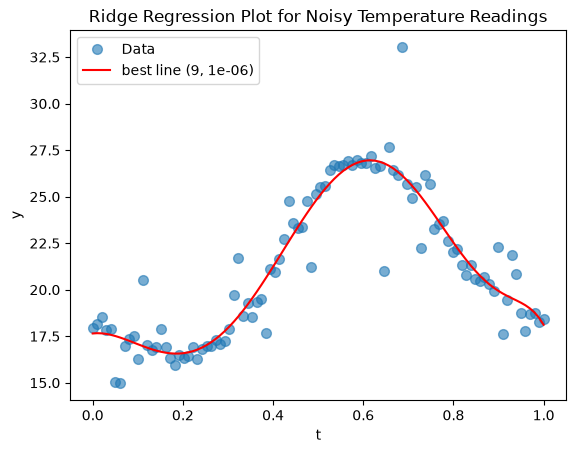

In [94]:
# easiest way is to plot against the full dataset.

def plot_polynomial(coeff_b):
    plt.plot(x_data, y_data, 'o', label='Data', markersize=7, alpha=0.6)
    plt.plot(x_data, polyval(x_data, coeff_b), 'r', label=f'best line ({M}, {lam})')
    plt.title(f'Ridge Regression Plot for Noisy Temperature Readings')
    plt.xlabel('t')
    plt.ylabel('y')
    plt.legend()
    plt.show()

plot_polynomial(omega_best)

Overall looks like a reasonable fit. There are some outlier points which the model doesn't attempt to fit to, since there are only a few of them compared to the 100 data points. There is a particularly high outlier at ~t=0.7. The model follows the trend closely, with only small wiggles near the end of the graph (t=~0.85 to t=1), likely from the high polynomial degree.

In [95]:
# introduce additional metrics for a better evaluation
from sklearn.metrics import r2_score, mean_absolute_percentage_error

y_pred = polyval(x_data, omega_best)

r2 = r2_score(y_data, y_pred)
mape = mean_absolute_percentage_error(y_data, y_pred)

print(f'Metrics report for degree: {M} and lambda: {lam}\n')
print(f'Mean Squared Error (MSE, 5-fold CV), lower=better (0 = best): {df_results['mse_test'][idx_min]:.3f}')
print(f'Mean Absolute Percentage Error (MAPE), lower=better (0% = best): {100*mape:.3f}%')
print(f'R2 Score, higher=better (1 = best): {r2:.3f}')

Metrics report for degree: 9 and lambda: 1e-06

Mean Squared Error (MSE, 5-fold CV), lower=better (0 = best): 2.116
Mean Absolute Percentage Error (MAPE), lower=better (0% = best): 3.709%
R2 Score, higher=better (1 = best): 0.873


Overall, the metrics are solid. MSE depends on the problem context, so MAPE and R2 score are more interpretable. A MAPE (error percentage) of 3.7% is generally considered excellent model performance. R2 score measures the "goodness of fit". With a score of 0.873, it can be said that my regression model explains 87.3% of the variability in the data. With noisy time-series data, a score of 0.873 is definitely reasonable.

Breakdown of Full Approach:
- Regression: decided to use polynomial ridge regression, as it is more straightforward and can still obtain strong results. I first rescaled t to the range of [0, 1] for conditioning reasonings and to match the first part of this homework. From there, I expanded the grid-search from M = 9 --> 12 and added in three new lambda values. The largest improvement was implementing k-Fold cross validation. This technique greatly improved the statistical soundness of my results, and made efficient use of the small 100 point dataset.
- Gaussian Mixture Models (GMM): this part was more straightforward. However, the GMM results were greatly improved from cross-validation because the residuals became more normalized. My final Gaussians were very reasonable: G1 was (-0.06, 0.14) corresponding to the ordinary sensor noise and G2 was (0.16, 6.33) corresponding to the malfunction measurements. The Gaussian metrics were used to confirm that K=2 is better than K=1.
- Evaluation: GMM was evaluated using the chart (which confirmed two reasonable Guassians) and the LogL1 and BIC scores. I brought in two additional metrics beyond MAE for my ridge regression line: MAPE and R2. These metrics are more interpretable and can be directly compared, like I mentioned in the prior cell.

Overall, the key aspects of my approach were implementing a larger grid-search and k-Fold cross validation. Those improvements resulted in a reasonable GMM with two Gaussians and strong regression results (MAPE = 3.709% and R2 of 0.873).

## Bonus Challenge I: Maximum Temperature (+10 points)

Using your regression model, estimate the maximum temperature over the time interval covered by the training data, $t \in [t_{\min}, t_{\max}]$.

That is, compute

$$
T_{\max,\text{pred}} = \max_{t \in [t_{\min}, t_{\max}]} \hat{s}(t),
$$

where $\hat{s}(t)$ is your estimated underlying (noise-free) temperature trend.

Submit a single numerical value for $T_{\max,\text{pred}}$.

I will compare your prediction to the true maximum temperature of the underlying signal used to generate the dataset. The closest prediction wins the bonus.

In [96]:
# already computed y_pred on the full dataset earlier, but run again

y_pred = polyval(x_data, omega_best)

max_temp = max(y_pred)

print(f'Maximum temperature over the t-interval is {max_temp}')

Maximum temperature over the t-interval is 26.95357138489814


## Bonus Challenge II: Noise Modeling (+10 points)

Your Gaussian mixture model describes two different levels of measurement noise.

Define the background sensor noise as the Gaussian component with the smaller standard deviation:

$$
\sigma_{\text{bg,pred}} = \min(\sigma_1, \sigma_2).
$$

Submit your estimated value of $\sigma_{\text{bg,pred}}$. I will compare it to the true background noise standard deviation used to generate the dataset.

The closest estimate wins the bonus.

In [97]:
# store std_devs in a list
std_devs = np.sqrt(covs2.ravel())

# find minimum
std_bg = min(std_devs)
print(f'Standard deviation for background noise is: {std_bg}')

Standard deviation for background noise is: 0.3824648819750573
